# Customer Retail Intelligence
### Predicting which customers will buy again in the next 90 days

**Dataset:** UCI Online Retail II, 1.07 million invoice lines from a UK online wholesaler of giftware, December 2009 to December 2011.
**Stack:** Python, DuckDB, dbt, scikit-learn, XGBoost, SHAP.

This notebook is the laboratory behind the project. It walks through every step in order, and each step ends with the decision it led to:

| # | Step | Question it answers |
|---|------|---------------------|
| 1 | Business problem | What decision will the model support, and how is success measured? |
| 2 | Data ingestion | What exactly did we receive? |
| 3 | Data audit | What is wrong with the data, and what rule fixes each issue? |
| 4 | Feature engineering with dbt | How do we build features without leaking the future? |
| 5 | Exploratory analysis | Which behaviours separate returning customers from the rest? |
| 6 | Validation design | How do we split the data so the score is honest? |
| 7 | Baselines and model comparison | Is machine learning worth it over a simple rule? |
| 8 | Holdout evaluation | How good is the chosen model, in technical and business terms? |
| 9 | Out-of-time validation | Does it still work on a later period? |
| 10 | Interpretability with SHAP | Why does the model score a customer the way it does? |
| 11 | Business impact | Who should marketing contact, and what is at stake? |
| 12 | Conclusions | What did we learn? |
| 13 | Limitations and next steps | What would we do with more time? |

The production code in `src/retail_intelligence/` reuses the same functions as this notebook (`retail_intelligence.modeling`), so the numbers here and in the deployed app come from one implementation.

In [1]:
import warnings
warnings.filterwarnings("ignore")   # keep the notebook output focused on results

import json

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import shap
from IPython.display import Markdown, display
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import precision_recall_curve, roc_curve
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, train_test_split

from retail_intelligence.config import (DATA_PROCESSED, DBT_DIR, FEATURE_LABELS, FEATURES, FIGURES,
                              LOYAL_THRESHOLD, NURTURE_THRESHOLD, RANDOM_STATE, RAW_PARQUET,
                              SNAPSHOTS, TARGET)
from retail_intelligence.features import load_snapshot
from retail_intelligence.modeling import (MONOTONE, calibration_table, evaluate, gains_table,
                                make_logistic, make_xgboost, shap_values)

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 30)

# One visual language for every chart in the project
BLUE, RED, GRAY, INK, MUTED = "#2a78d6", "#e34948", "#9aa0a6", "#1f2328", "#5f6368"
STATUS = {"Loyal": "#0ca30c", "Nurture": "#fab219", "At risk": "#d03b3b"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.figsize": (9, 4.2),
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9ccd1",
    "axes.grid": True, "grid.color": "#ececec", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
    "legend.frameon": False,
})
FIGURES.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()

## 1. Business problem

An online wholesaler sells to about 5,900 business customers (mostly gift shops). Marketing has a fixed budget for retention campaigns and today treats every customer the same way. The question is:

> **Which customers are likely to buy again in the next 90 days, and which valuable customers are drifting away?**

**Decision supported.** Each customer gets a probability of ordering again within 90 days. The probability is turned into three segments and a next-best action:

| Segment | Probability | Action |
|---|---|---|
| Loyal | 0.60 or more | Loyalty reward, no discount needed |
| Nurture | 0.30 to 0.60 | Cross-sell to raise engagement |
| At risk | below 0.30 | Win-back offer, prioritised when the customer is high value (top 20% by spend) |

**Target definition.** `label = 1` if the customer places at least one non-cancelled order in the 90 days after a cutoff date. Ninety days matches a quarterly campaign cycle and is long enough to cover the typical gap between wholesale orders.

**How success is measured.**
- *Ranking quality* (ROC AUC, average precision): does the model put future buyers above non-buyers?
- *Probability quality* (Brier score, log loss, calibration): can a 0.7 be read as "about 70%"? The segment thresholds depend on it.
- *Business metric* (capture and lift at the top 20%): if marketing can only contact one customer in five, what share of all future buyers does that list contain?

## 2. Data ingestion

The raw file is the UCI Excel workbook with one sheet per year. `python -m retail_intelligence.ingest` reads both sheets, standardises column names, fixes types (invoice and stock codes mix numbers and text) and writes a single Parquet file. Parquet is about 15 times smaller than the Excel file and loads in under a second, and it is the source that dbt reads.

In [2]:
raw = pd.read_parquet(RAW_PARQUET)
print(f"{len(raw):,} rows x {raw.shape[1]} columns")
print(f"Period: {raw.invoice_date.min():%Y-%m-%d} to {raw.invoice_date.max():%Y-%m-%d}")
print(f"Invoices: {raw.invoice.nunique():,} | Products: {raw.stock_code.nunique():,} | "
      f"Customers: {raw.customer_id.nunique():,} | Countries: {raw.country.nunique()}")
raw.head()

1,067,371 rows x 8 columns
Period: 2009-12-01 to 2011-12-09
Invoices: 53,628 | Products: 5,305 | Customers: 5,942 | Countries: 43


,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.950,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.100,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.250,13085,United Kingdom


In [3]:
schema = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_pct": raw.isna().mean(),
    "distinct": raw.nunique(),
    "example": raw.iloc[0],
})
schema.style.format({"missing": "{:,}", "missing_pct": "{:.1%}", "distinct": "{:,}"})

,dtype,missing,missing_pct,distinct,example
invoice,string,0,0.0%,"53,628",489434
stock_code,string,0,0.0%,"5,305",85048
description,string,"4,382",0.4%,"5,698",15CM CHRISTMAS GLASS BALL 20 LIGHTS
quantity,int64,0,0.0%,"1,057",12
invoice_date,datetime64[us],0,0.0%,"47,635",2009-12-01 07:45:00
price,float64,0,0.0%,"2,807",6.950000
customer_id,Int64,"243,007",22.8%,"5,942",13085
country,string,0,0.0%,43,United Kingdom


Each row is one product line on an invoice. Invoices starting with `C` are cancellations and `customer_id` is the only link to a customer, so its completeness matters more than any other column.

## 3. Data audit

Before any modelling, every column is checked for problems that would distort customer behaviour. Each finding below ends with a decision, and each decision became a rule in the dbt staging model `stg_transactions.sql`, so the cleaning is versioned, tested and repeatable instead of living in a notebook cell.

In [4]:
is_cancel = raw.invoice.str.startswith("C")
code_upper = raw.stock_code.str.upper()
NON_PRODUCT = ["POST", "DOT", "M", "C2", "D", "S", "B", "BANK CHARGES", "ADJUST",
               "AMAZONFEE", "PADS", "CRUK", "TEST001", "TEST002"]

checks = pd.DataFrame([
    ("Missing customer ID", raw.customer_id.isna().sum(), "Drop: cannot be linked to a customer", "Rule 2"),
    ("Exact duplicate lines", raw.duplicated().sum(), "Drop: system double-posts", "Rule 1"),
    ("Cancellation lines (invoice starts with C)", is_cancel.sum(), "Keep, flag as returns (feature: return_rate)", "is_cancellation"),
    ("Negative quantity, not a cancellation", ((raw.quantity < 0) & ~is_cancel).sum(), "Drop: stock adjustments, all have price 0", "Rule 3"),
    ("Price zero or negative", (raw.price <= 0).sum(), "Drop: free samples and accounting entries", "Rule 3"),
    ("Bad-debt adjustments (invoice starts with A)", raw.invoice.str.startswith("A").sum(), "Drop: not customer activity", "Rule 4"),
    ("Non-merchandise stock codes", code_upper.isin(NON_PRODUCT).sum(), "Drop: postage, fees, manual entries, tests", "Rule 5"),
    ("Missing description", raw.description.isna().sum(), "No action: description is not used", "-"),
], columns=["check", "rows", "decision", "dbt rule"])
checks["share"] = checks["rows"] / len(raw)
checks.style.format({"rows": "{:,}", "share": "{:.2%}"}).hide(axis="index")

check,rows,decision,dbt rule,share
Missing customer ID,"243,007",Drop: cannot be linked to a customer,Rule 2,22.77%
Exact duplicate lines,"34,335",Drop: system double-posts,Rule 1,3.22%
Cancellation lines (invoice starts with C),"19,494","Keep, flag as returns (feature: return_rate)",is_cancellation,1.83%
"Negative quantity, not a cancellation","3,457","Drop: stock adjustments, all have price 0",Rule 3,0.32%
Price zero or negative,"6,207",Drop: free samples and accounting entries,Rule 3,0.58%
Bad-debt adjustments (invoice starts with A),6,Drop: not customer activity,Rule 4,0.00%
Non-merchandise stock codes,"5,827","Drop: postage, fees, manual entries, tests",Rule 5,0.55%
Missing description,"4,382",No action: description is not used,-,0.41%


**Missing customer IDs are the largest issue (about 23% of lines).** They are guest or anonymous orders. They cannot be used for a customer-level model, so they are dropped. This is safe for our question but means the model only applies to registered customers.

**Non-merchandise stock codes.** A look at the most frequent codes that are not normal product codes shows postage, manual adjustments and bank fees. Including them would inflate spend and order counts for customers who simply paid shipping.

In [5]:
odd = raw[~raw.stock_code.str.match(r"^\d{5}", na=False)]
(odd.groupby(code_upper[odd.index])
    .agg(lines=("invoice", "size"), example=("description", "first"), revenue=("price", lambda s: (s * odd.loc[s.index, "quantity"]).sum()))
    .sort_values("lines", ascending=False).head(12))

,lines,example,revenue
stock_code,,,
POST,2122,POSTAGE,"112,341.000"
DOT,1446,DOTCOM POSTAGE,"322,647.470"
M,1426,Manual,"-82,781.270"
C2,282,CARRIAGE,"13,386.000"
D,177,Discount,"-13,484.540"
S,104,SAMPLES,"-6,065.800"
BANK CHARGES,102,Bank Charges,"-35,562.629"
ADJUST,67,Adjustment by john on 26/01/2010 16,"6,835.240"
AMAZONFEE,43,AMAZON FEE,"-260,763.580"


Gift vouchers (`gift_0001_*`) and `DCGS*` product codes look unusual but are real merchandise, so they are kept. Only the codes listed in `dbt_project.yml` under `non_product_codes` are removed.

**Outliers.** Quantities and prices have extreme tails (a single order line of 80,995 units, a price of £38,970 for a manual adjustment). Extreme lines are mostly either cancelled straight away or belong to the non-product codes above, so the rules already remove them. Real wholesale customers do place very large orders, so no further capping is applied at the line level; the model works on log-scaled or tree-based features that are robust to skew.

In [6]:
print(raw[["quantity", "price"]].quantile([0.001, 0.01, 0.5, 0.99, 0.999]).T.to_string())
print()
print("Largest single line by quantity:")
print(raw.loc[raw.quantity.abs().nlargest(4).index, ["invoice", "stock_code", "description", "quantity", "price", "customer_id"]].to_string())

            0.001  0.010  0.500   0.990   0.999
quantity -112.630 -3.000  3.000 100.000 500.000
price       0.000  0.210  2.100  18.000 217.016

Largest single line by quantity:
         invoice stock_code                     description  quantity  price  customer_id
1065882   581483      23843     PAPER CRAFT , LITTLE BIRDIE     80995  2.080        16446
1065883  C581484      23843     PAPER CRAFT , LITTLE BIRDIE    -80995  2.080        16446
587080    541431      23166  MEDIUM CERAMIC TOP STORAGE JAR     74215  1.040        12346
587085   C541433      23166  MEDIUM CERAMIC TOP STORAGE JAR    -74215  1.040        12346


**Geography.** The business is concentrated in the UK, so a country flag (`is_uk`) is enough; one-hot encoding 43 countries would add noise for little signal.

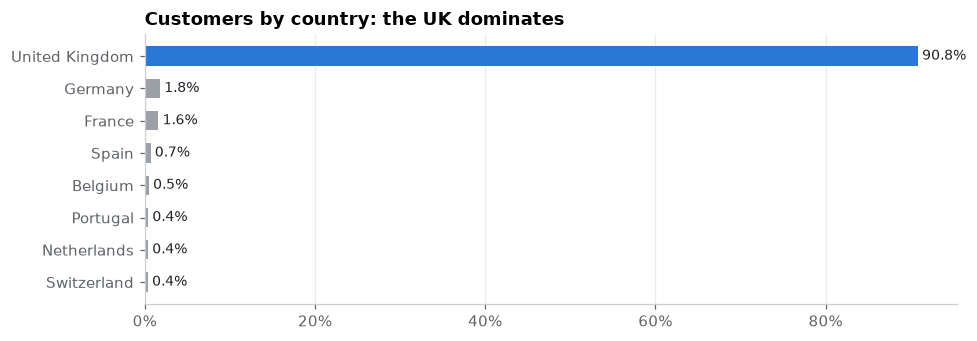

In [7]:
country = raw.dropna(subset=["customer_id"]).groupby("country").customer_id.nunique().sort_values(ascending=False)
share = (country / country.sum()).head(8)
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(share.index[::-1], share.values[::-1], color=[GRAY] * 7 + [BLUE], height=0.6)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title("Customers by country: the UK dominates")
for y, v in enumerate(share.values[::-1]):
    ax.text(v + 0.005, y, f"{v:.1%}", va="center", color=INK, fontsize=9)
ax.grid(axis="y", visible=False)
save(fig, "retention_01_customers_by_country")

### Audit result after dbt cleaning

The rules are applied in `dbt/models/staging/stg_transactions.sql`. Below we read the cleaned view straight from the DuckDB warehouse that dbt built, to confirm what is left.

In [8]:
con = duckdb.connect(str(DATA_PROCESSED / "warehouse.duckdb"), read_only=True)
con.execute(f"SET file_search_path = '{DBT_DIR}'")   # the view reads the Parquet file relative to dbt/
clean = con.sql("""
    select count(*) as lines,
           count(distinct invoice_id) as invoices,
           count(distinct customer_id) as customers,
           avg(is_cancellation::int) as cancellation_share,
           min(invoiced_at) as first_day, max(invoiced_at) as last_day
    from stg_transactions
""").df()
clean["kept_share"] = clean["lines"] / len(raw)
clean

,lines,invoices,customers,cancellation_share,first_day,last_day,kept_share
0,794168,43879,5875,0.022,2009-12-01 07:45:00,2011-12-09 12:50:00,0.744


About 75% of lines survive. Every rule is covered by dbt tests (`not_null`, a custom `positive` generic test on prices, and singular tests on the final feature table), which run on every build and in CI.

## 4. Feature engineering with dbt: the snapshot design

The most common mistake in churn and repurchase models is **leakage**: computing features with information from the period the model is supposed to predict. A model trained like that looks excellent in a notebook and fails in production.

To prevent it, the dbt project builds **snapshots**. A snapshot freezes time at a cutoff date:

```
          features: only transactions BEFORE the cutoff          label window
|--------------------------------------------------------------|============|
Dec 2009                                                     cutoff     cutoff + 90 days
```

The same SQL is run with different `cutoff_date` variables (`python -m retail_intelligence.features`):

| Snapshot | Cutoff | Role |
|---|---|---|
| `features_2011_06_01` | 1 Jun 2011 | Earlier period, used to test the model out of time |
| `features_2011_09_01` | 1 Sep 2011 | Latest period with a complete 90-day label: training |
| `features_current` | 10 Dec 2011 | The day after the data ends: customers to score today (no label yet) |

The dbt lineage is `stg_transactions` (cleaning) → `int_customer_history` (orders, spend, returns before the cutoff) and `int_repurchases` (orders inside the label window) → `customer_features` (one row per customer). Two singular dbt tests guard the design: `assert_no_label_leakage` checks that no feature is computed from transactions on or after the cutoff, and `assert_valid_feature_ranges` checks the ranges of every feature.

In [9]:
features_dictionary = pd.DataFrame({
    "feature": FEATURES,
    "description": [FEATURE_LABELS[f] for f in FEATURES],
    "definition": [
        "Days between the last order and the cutoff",
        "Distinct non-cancelled invoices before the cutoff",
        "Net revenue before the cutoff (sales minus returns), GBP",
        "Net revenue divided by number of orders, GBP",
        "Distinct stock codes bought",
        "Days between the first order and the cutoff",
        "Cancelled invoices divided by orders",
        "Orders in the 90 days before the cutoff (recent momentum)",
        "Average gap between consecutive orders; empty for one-order customers",
        "1 if the customer is in the United Kingdom",
    ],
})
features_dictionary.style.hide(axis="index")

feature,description,definition
recency_days,Days since last purchase,Days between the last order and the cutoff
frequency,Number of orders,Distinct non-cancelled invoices before the cutoff
monetary,Total spent (GBP),"Net revenue before the cutoff (sales minus returns), GBP"
avg_order_value,Average order value (GBP),"Net revenue divided by number of orders, GBP"
unique_products,Distinct products bought,Distinct stock codes bought
tenure_days,Days as customer,Days between the first order and the cutoff
return_rate,Return rate,Cancelled invoices divided by orders
orders_last_90d,Orders in last 90 days,Orders in the 90 days before the cutoff (recent momentum)
avg_days_between_orders,Average days between orders,Average gap between consecutive orders; empty for one-order customers
is_uk,UK customer,1 if the customer is in the United Kingdom


In [10]:
snapshots = {name: load_snapshot(name) for name in SNAPSHOTS}
summary = pd.DataFrame([
    {"snapshot": n, "cutoff": SNAPSHOTS[n], "customers": len(d),
     "repurchase_rate": d[TARGET].mean() if n != "features_current" else np.nan}
    for n, d in snapshots.items()
])
summary.style.format({"customers": "{:,}", "repurchase_rate": "{:.1%}"}, na_rep="unknown (future)").hide(axis="index")

snapshot,cutoff,customers,repurchase_rate
features_2011_06_01,2011-06-01,"4,908",32.9%
features_2011_09_01,2011-09-01,"5,224",42.8%
features_current,2011-12-10,"5,852",unknown (future)


The repurchase rate jumps from 32.9% in the June snapshot to 42.8% in the September one. That is not noise; it is seasonality, and it shapes the rest of the analysis. The next section shows why.

## 5. Exploratory analysis

### 5.1 The business is strongly seasonal

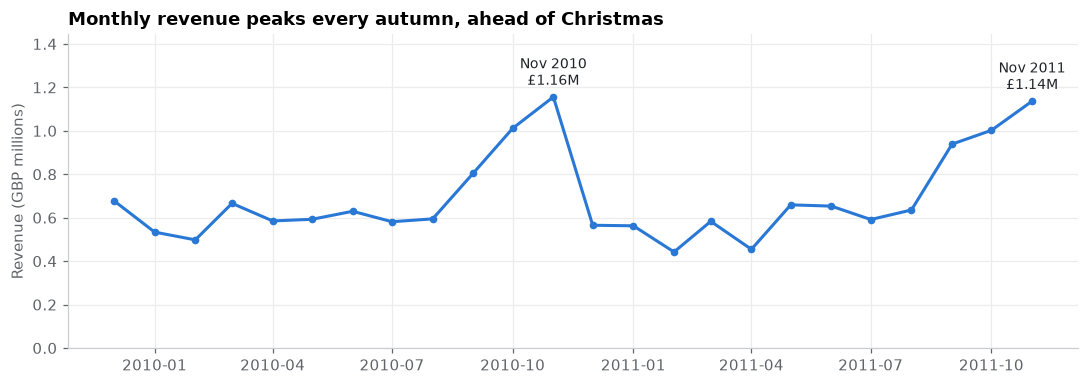

In [11]:
monthly = con.sql("""
    select date_trunc('month', invoiced_at) as month,
           sum(revenue) filter (where not is_cancellation) as revenue,
           count(distinct customer_id) as active_customers
    from stg_transactions
    where invoiced_at < '2011-12-01'
    group by 1 order by 1
""").df()

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(monthly.month, monthly.revenue / 1e6, color=BLUE, lw=2, marker="o", ms=4)
for year in (2010, 2011):
    peak = monthly[monthly.month.dt.year == year].nlargest(1, "revenue").iloc[0]
    ax.annotate(f"{peak.month:%b %Y}\n£{peak.revenue/1e6:.2f}M", (peak.month, peak.revenue / 1e6),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, color=INK)
ax.set_ylabel("Revenue (GBP millions)")
ax.set_ylim(0, monthly.revenue.max() / 1e6 * 1.25)
ax.set_title("Monthly revenue peaks every autumn, ahead of Christmas")
save(fig, "retention_02_monthly_revenue")

Gift shops stock up from September to November. A 90-day window starting in September covers the busiest quarter of the year; one starting in June covers the summer. To see how much this moves the target, the next query computes the repurchase rate for a cutoff at the start of every month.

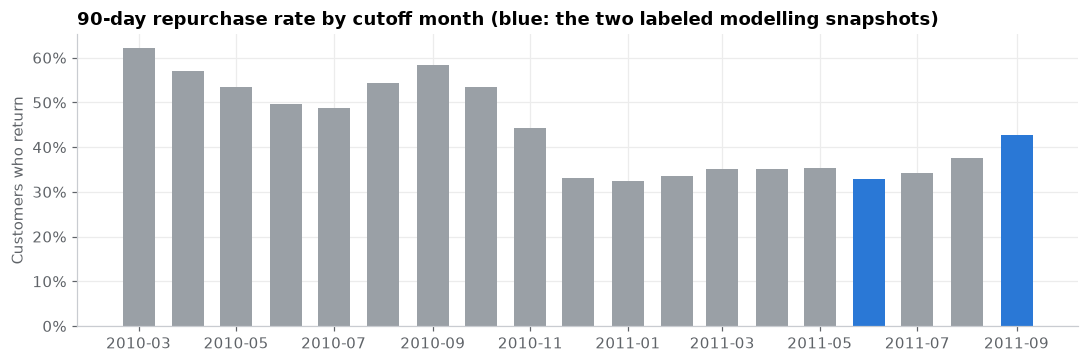

month,Jun,Sep,gap
year,,,
2010,49.7%,58.3%,8.6%
2011,32.9%,42.8%,9.9%


In [12]:
seasonal = con.sql("""
    with orders as (
        select distinct customer_id, invoiced_at::date as day
        from stg_transactions where not is_cancellation
    ),
    cutoffs as (
        select unnest(generate_series(date '2010-03-01', date '2011-09-01', interval 1 month))::date as cutoff
    )
    select c.cutoff,
           count(distinct o.customer_id) filter (where o.day < c.cutoff) as customers,
           count(distinct o.customer_id) filter (
               where o.day >= c.cutoff and o.day < c.cutoff + interval 90 day
                 and o.customer_id in (select customer_id from orders where day < c.cutoff)
           ) as returned
    from cutoffs c cross join orders o
    group by 1 order by 1
""").df()
seasonal["rate"] = seasonal.returned / seasonal.customers

fig, ax = plt.subplots(figsize=(10, 3.4))
colors = [BLUE if m in (6, 9) and y == 2011 else GRAY for m, y in zip(seasonal.cutoff.dt.month, seasonal.cutoff.dt.year)]
ax.bar(seasonal.cutoff, seasonal.rate, width=20, color=colors)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title("90-day repurchase rate by cutoff month (blue: the two labeled modelling snapshots)")
ax.set_ylabel("Customers who return")
save(fig, "retention_03_repurchase_rate_by_cutoff")
(seasonal.assign(year=seasonal.cutoff.dt.year, month=seasonal.cutoff.dt.strftime("%b"))
         .query("month in ['Jun', 'Sep']")
         .pivot(index="year", columns="month", values="rate")[["Jun", "Sep"]]
         .assign(gap=lambda t: t.Sep - t.Jun)
         .style.format("{:.1%}"))

**Finding.** Two effects are visible.

- *History length.* In 2010 the data had only started a few months earlier, so every known customer was a recent one and rates look high (50 to 62%). As history accumulates, more lapsed customers enter the base and the rate settles in the 30s. This is why the modelling snapshots are taken in 2011, when each customer has at least 18 months of observable history.
- *Season.* Within the same year, a September cutoff is 9 to 10 points higher than a June cutoff: 58% vs 50% in 2010 and 43% vs 33% in 2011. The 90 days after September cover the Christmas buying season.

A model trained in one season will therefore be miscalibrated in another, even if it ranks customers correctly. This is tested explicitly in section 9.

### 5.2 Target balance and feature distributions (training snapshot)

In [13]:
df = snapshots["features_2011_09_01"].copy()
print(f"Training snapshot: {len(df):,} customers, {df[TARGET].mean():.1%} repurchased within 90 days")
df[FEATURES].describe(percentiles=[0.25, 0.5, 0.75, 0.99]).T

Training snapshot: 5,224 customers, 42.8% repurchased within 90 days


,count,mean,std,min,25%,50%,75%,99%,max
recency_days,"5,224.000",204.085,170.776,1.000,50.000,161.000,318.000,630.770,639.000
frequency,"5,224.000",5.654,11.066,1.000,1.000,3.000,6.000,41.770,278.000
monetary,"5,224.000","2,580.297","11,946.499",1.550,315.352,775.745,"2,044.392","26,213.165","451,866.970"
avg_order_value,"5,224.000",370.802,641.614,1.550,173.998,275.555,408.075,"1,893.407","25,784.320"
unique_products,"5,224.000",74.105,104.250,1.000,18.000,41.000,91.000,456.550,"2,164.000"
tenure_days,"5,224.000",425.283,178.123,1.000,304.000,466.000,578.000,639.000,639.000
return_rate,"5,224.000",0.191,0.336,0.000,0.000,0.000,0.273,1.500,4.000
orders_last_90d,"5,224.000",0.746,1.747,0.000,0.000,0.000,1.000,7.000,44.000
avg_days_between_orders,"3,642.000",90.193,80.534,0.000,38.425,67.300,116.500,393.590,612.000
is_uk,"5,224.000",0.914,0.281,0.000,1.000,1.000,1.000,1.000,1.000


The classes are reasonably balanced (43% positive), so no resampling or class weights are needed. Spend, frequency and product counts are heavily right-skewed: the median customer placed 3 orders and spent about £776, while the largest spent more than £450,000. Log scales are used in the charts below, and the linear model uses log-transformed inputs.

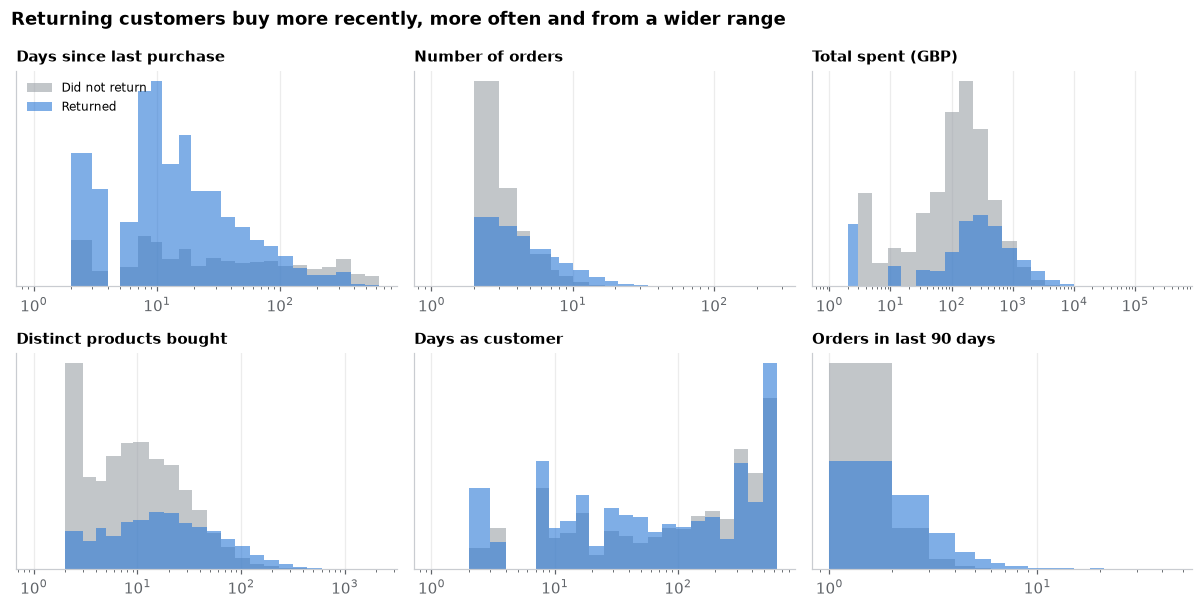

In [14]:
plot_feats = ["recency_days", "frequency", "monetary", "unique_products", "tenure_days", "orders_last_90d"]
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6))
for ax, f in zip(axes.ravel(), plot_feats):
    bins = np.unique(np.round(np.logspace(0, np.log10(df[f].max() + 2), 25)))
    for lab, color, name in [(0, GRAY, "Did not return"), (1, BLUE, "Returned")]:
        ax.hist(df.loc[df[TARGET] == lab, f] + 1, bins=bins, color=color, alpha=0.6, label=name, density=True)
    ax.set_xscale("log")
    ax.set_title(FEATURE_LABELS[f], fontsize=10)
    ax.set_yticks([])
axes[0, 0].legend(loc="upper left", fontsize=8)
fig.suptitle("Returning customers buy more recently, more often and from a wider range", x=0.01, ha="left", fontweight="bold")
save(fig, "retention_04_feature_distributions")

### 5.3 Recency and frequency: the two strongest signals

Classic RFM thinking says recent and frequent buyers come back. The data confirms it, and shows how strong the effect is.

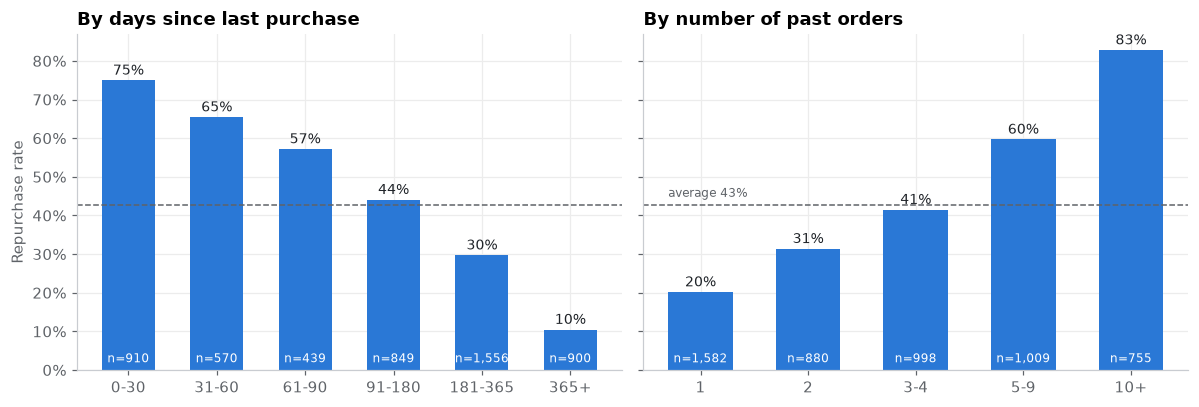

In [15]:
df["recency_bucket"] = pd.cut(df.recency_days, [-1, 30, 60, 90, 180, 365, 10_000],
                              labels=["0-30", "31-60", "61-90", "91-180", "181-365", "365+"])
df["frequency_bucket"] = pd.cut(df.frequency, [0, 1, 2, 4, 9, 10_000], labels=["1", "2", "3-4", "5-9", "10+"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, col, title in [(axes[0], "recency_bucket", "By days since last purchase"),
                       (axes[1], "frequency_bucket", "By number of past orders")]:
    g = df.groupby(col, observed=True)[TARGET].agg(["mean", "size"])
    ax.bar(g.index.astype(str), g["mean"], color=BLUE, width=0.6)
    for i, (rate, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, rate + 0.015, f"{rate:.0%}", ha="center", fontsize=9, color=INK)
        ax.text(i, 0.02, f"n={n:,}", ha="center", fontsize=8, color="white")
    ax.axhline(df[TARGET].mean(), color=MUTED, ls="--", lw=1)
    ax.set_title(title)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[0].set_ylabel("Repurchase rate")
axes[1].text(-0.3, df[TARGET].mean() + 0.02, f"average {df[TARGET].mean():.0%}", color=MUTED, fontsize=8)
save(fig, "retention_05_rate_by_recency_frequency")

**Finding.** Customers who ordered in the last 30 days return 75% of the time, about seven times the rate of customers silent for more than a year (10%). Customers with 10 or more orders return 83% of the time, against 20% for one-time buyers. Both relationships are monotonic, which later justifies **monotone constraints** in the model: the model is not allowed to learn that a more recent or more frequent customer is less likely to return.

### 5.4 The two signals interact

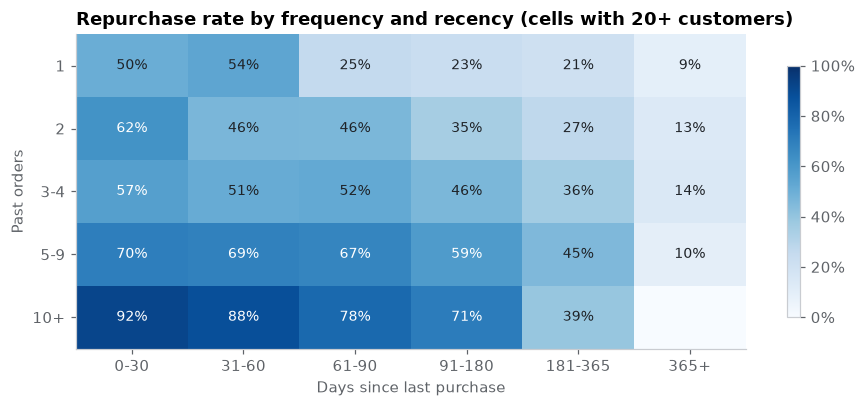

In [16]:
pivot = df.pivot_table(index="frequency_bucket", columns="recency_bucket", values=TARGET, aggfunc="mean", observed=True)
counts = df.pivot_table(index="frequency_bucket", columns="recency_bucket", values=TARGET, aggfunc="size", observed=True)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
im = ax.imshow(pivot.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(pivot.shape[1]), pivot.columns.astype(str))
ax.set_yticks(range(pivot.shape[0]), pivot.index.astype(str))
ax.set_xlabel("Days since last purchase"); ax.set_ylabel("Past orders")
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v, n = pivot.values[i, j], counts.values[i, j]
        if not np.isnan(v) and n >= 20:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=9, color="white" if v > 0.55 else INK)
ax.grid(False)
ax.set_title("Repurchase rate by frequency and recency (cells with 20+ customers)")
fig.colorbar(im, ax=ax, format=mtick.PercentFormatter(1), shrink=0.8)
save(fig, "retention_06_rf_heatmap")

A frequent customer who has been quiet for six months is still more likely to return than a one-time buyer from last month. Simple rules based on one dimension miss this, which is the first argument for a multivariate model.

### 5.5 Correlations and redundancy

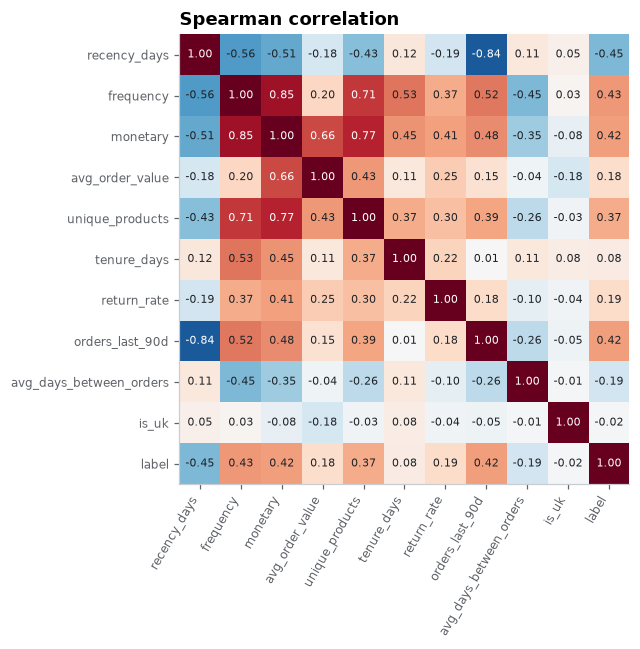

,correlation with label
recency_days,-0.446
frequency,0.430
orders_last_90d,0.416
monetary,0.416
unique_products,0.373
avg_days_between_orders,-0.189
return_rate,0.185
avg_order_value,0.178
tenure_days,0.085
is_uk,-0.023


In [17]:
corr = df[FEATURES + [TARGET]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
labels = FEATURES + [TARGET]
ax.set_xticks(range(len(labels)), labels, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(labels)), labels, fontsize=8)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.values[i, j]) > 0.6 else INK)
ax.grid(False)
ax.set_title("Spearman correlation")
save(fig, "retention_07_correlation")
corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).to_frame("correlation with label")

**Findings.**
- Frequency, product variety and spend are strongly correlated with each other (0.7 to 0.85): they all measure "how big is this customer". Trees handle this well; for the linear model it means individual coefficients should not be over-interpreted.
- Recency has the strongest single correlation with the label (negative: the longer the silence, the lower the chance).
- `return_rate` can exceed 1 for a few customers (more cancelled invoices than orders, typically when an old order is returned after the cutoff window of its purchase). It is kept as is because the tree model is insensitive to the scale, and the dbt range test allows it explicitly.

## 6. Validation design

Three layers of validation, each answering a different question:

1. **Stratified 80/20 holdout** on the September snapshot. The 20% test set is touched once, at the end, to report final numbers.
2. **Repeated stratified 5-fold cross-validation (3 repeats, 15 fits per model)** on the 80% training part. Used to compare models and choose one. Fifteen scores give a mean and a standard deviation, so we can tell a real difference from noise.
3. **Out-of-time test**: train on the June snapshot, test on the September snapshot. This is the closest simulation of production, where a model trained on the past scores the future.

Customers are the unit of observation and each appears once per snapshot, so a random split by row is a split by customer; there is no customer overlap between train and test inside a snapshot.

In [18]:
train, test = train_test_split(df, test_size=0.2, stratify=df[TARGET], random_state=RANDOM_STATE)
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
print(f"Train: {len(train):,} customers ({y_train.mean():.1%} positive)")
print(f"Test:  {len(test):,} customers ({y_test.mean():.1%} positive)")
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

Train: 4,179 customers (42.8% positive)
Test:  1,045 customers (42.8% positive)


## 7. Baselines and model comparison

A model has to beat simple alternatives to be worth deploying:

- **Recency rule**: rank customers by days since last purchase. No training at all; this is what many teams do in a spreadsheet.
- **Logistic regression** on log-transformed, standardised features: the interpretable statistical baseline.

Then three tree ensembles: random forest, scikit-learn's histogram gradient boosting, and XGBoost (default settings, a tuned shallow configuration, and the tuned configuration with monotone constraints).

In [19]:
from sklearn.metrics import roc_auc_score
recency_auc = roc_auc_score(y_train, -X_train.recency_days)
frequency_auc = roc_auc_score(y_train, X_train.frequency)
print(f"Recency rule AUC (train): {recency_auc:.3f}")
print(f"Frequency rule AUC (train): {frequency_auc:.3f}")

Recency rule AUC (train): 0.763
Frequency rule AUC (train): 0.750


In [20]:
candidates = {
    "Logistic regression": make_logistic(),
    "Random forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=20, n_jobs=-1, random_state=RANDOM_STATE),
    "Hist gradient boosting": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300, random_state=RANDOM_STATE),
    "XGBoost (default)": make_xgboost(monotone=False, n_estimators=100, max_depth=6, learning_rate=0.3,
                                      subsample=1.0, colsample_bytree=1.0, min_child_weight=1),
    "XGBoost (tuned)": make_xgboost(monotone=False),
    "XGBoost (tuned, monotone)": make_xgboost(monotone=True),
}
rows = []
for name, model in candidates.items():
    X_cv = X_train.fillna(-1) if name == "Random forest" else X_train   # RF cannot take missing values
    r = cross_validate(model, X_cv, y_train, cv=cv, n_jobs=-1,
                       scoring={"auc": "roc_auc", "ap": "average_precision", "brier": "neg_brier_score"})
    rows.append({"model": name, "auc_mean": r["test_auc"].mean(), "auc_std": r["test_auc"].std(),
                 "average_precision": r["test_ap"].mean(), "brier": -r["test_brier"].mean()})
comparison = pd.DataFrame(rows).sort_values("auc_mean", ascending=False).reset_index(drop=True)
comparison

,model,auc_mean,auc_std,average_precision,brier
0,Random forest,0.805,0.015,0.778,0.175
1,XGBoost (tuned),0.803,0.014,0.775,0.176
2,"XGBoost (tuned, monotone)",0.802,0.015,0.773,0.177
3,Hist gradient boosting,0.798,0.015,0.770,0.178
4,Logistic regression,0.793,0.016,0.761,0.181
5,XGBoost (default),0.770,0.014,0.742,0.201


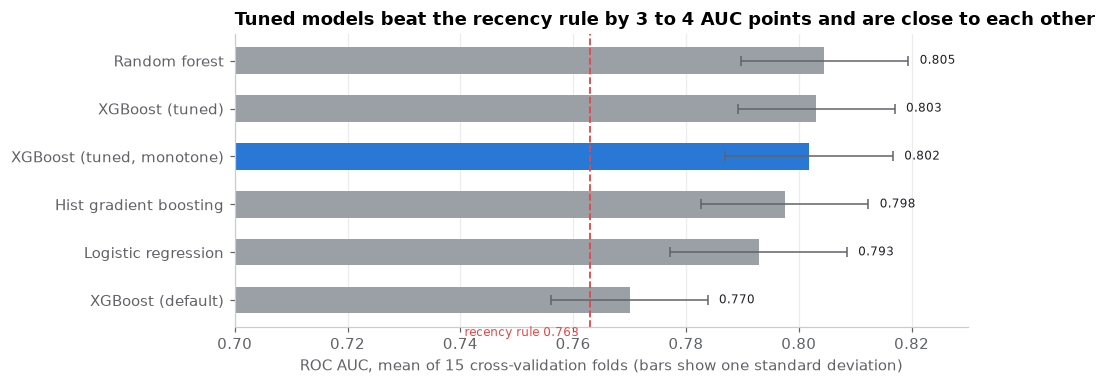

In [21]:
c = comparison.sort_values("auc_mean")
fig, ax = plt.subplots(figsize=(9, 3.6))
colors = [BLUE if m == "XGBoost (tuned, monotone)" else GRAY for m in c.model]
ax.barh(c.model, c.auc_mean, xerr=c.auc_std, color=colors, height=0.55, error_kw={"ecolor": MUTED, "lw": 1, "capsize": 3})
ax.axvline(recency_auc, color=RED, ls="--", lw=1.2)
ax.text(recency_auc - 0.002, -0.75, f"recency rule {recency_auc:.3f}", color=RED, fontsize=8, ha="right")
ax.set_xlim(0.70, 0.83)
ax.set_xlabel("ROC AUC, mean of 15 cross-validation folds (bars show one standard deviation)")
ax.set_title("Tuned models beat the recency rule by 3 to 4 AUC points and are close to each other")
for y, (m, s) in enumerate(zip(c.auc_mean, c.auc_std)):
    ax.text(m + s + 0.002, y, f"{m:.3f}", va="center", fontsize=8, color=INK)
ax.grid(axis="y", visible=False)
save(fig, "retention_08_model_comparison")

### Model selection

**What the comparison says.**
- The tuned models beat the recency rule (0.763 on the same training data) by 3 to 4 AUC points: the multivariate signal is real.
- Default XGBoost (deep trees, high learning rate) is the *worst* model: it overfits a 4,000-row dataset. Shallow, slowly learned trees fix that.
- The tuned tree models (random forest, histogram boosting, XGBoost) are tied at about 0.80, within one standard deviation (about 0.015) of each other, and logistic regression is less than one standard deviation behind. With about 5,000 customers and 10 behavioural features, the signal is mostly smooth and monotonic, so a well-specified linear model is a strong competitor. That is a useful result, not a disappointing one.

**Chosen model: XGBoost (tuned, monotone).** On equal accuracy, the decision rests on properties that matter in production:

| Criterion | Why XGBoost wins |
|---|---|
| Accuracy | Within 0.003 AUC and 0.002 Brier of the best model, a fraction of one standard deviation; the constraints cost almost nothing |
| Business logic | Monotone constraints guarantee that more recent, more frequent, higher spending customers never score lower, at almost no cost in AUC |
| Missing values | One-order customers have no inter-order gap; XGBoost learns where to send them instead of relying on imputation |
| Explanations | Exact TreeSHAP values are computed natively by XGBoost, so every score in the app has a faithful explanation |
| Robustness | No scaling or log transforms needed; insensitive to the spend outliers kept in section 3. The random forest scores the same but needs imputation, has no monotone option and is slower to explain |

Logistic regression stays in the project as the benchmark that any future model has to beat.

## 8. Holdout evaluation

The chosen model is trained on the 80% training set and evaluated once on the 20% test set it has never seen.

In [22]:
model = make_xgboost().fit(X_train, y_train)
p_test = model.predict_proba(X_test)[:, 1]
logit = make_logistic().fit(X_train, y_train)
p_logit = logit.predict_proba(X_test)[:, 1]

results = pd.DataFrame({
    "XGBoost (chosen)": evaluate(y_test, p_test),
    "Logistic regression": evaluate(y_test, p_logit),
}).T
results["recency rule AUC"] = roc_auc_score(y_test, -X_test.recency_days)
results

,auc,average_precision,brier,log_loss,capture_top20,lift_top20,base_rate,mean_prediction,recency rule AUC
XGBoost (chosen),0.786,0.749,0.185,0.551,0.376,1.879,0.428,0.431,0.748
Logistic regression,0.780,0.737,0.187,0.553,0.367,1.834,0.428,0.430,0.748


On this particular 20% split the two models are again within noise of each other (the cross-validation standard deviation is about 0.013 AUC), which confirms the conclusion from section 7. What matters for the business is the last group of metrics: **contacting the top 20% of customers ranked by the model reaches about 38% of all customers who will buy again, almost twice what a random list of the same size would reach.**

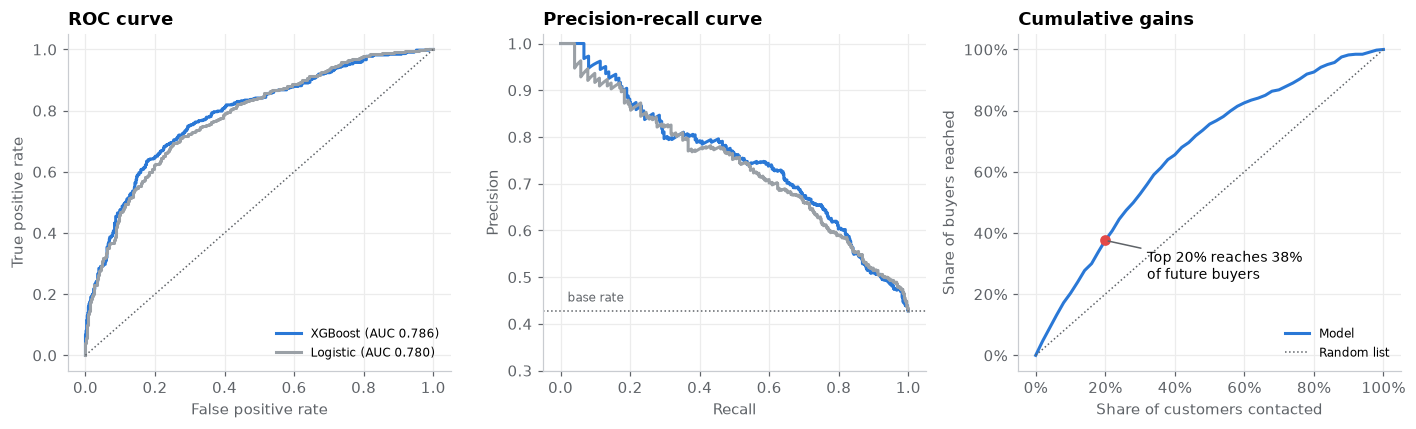

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
# ROC
for p, name, color in [(p_test, "XGBoost", BLUE), (p_logit, "Logistic", GRAY)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], color=MUTED, ls=":", lw=1)
axes[0].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")
axes[0].legend(loc="lower right", fontsize=8)
# Precision-recall
for p, name, color in [(p_test, "XGBoost", BLUE), (p_logit, "Logistic", GRAY)]:
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, color=color, lw=2, label=name)
axes[1].axhline(y_test.mean(), color=MUTED, ls=":", lw=1)
axes[1].text(0.02, y_test.mean() + 0.02, "base rate", color=MUTED, fontsize=8)
axes[1].set(title="Precision-recall curve", xlabel="Recall", ylabel="Precision", ylim=(0.3, 1.02))
# Gains
g = gains_table(y_test, p_test)
axes[2].plot(g.pct_contacted, g.pct_captured, color=BLUE, lw=2, label="Model")
axes[2].plot([0, 1], [0, 1], color=MUTED, ls=":", lw=1, label="Random list")
cap = evaluate(y_test, p_test)["capture_top20"]
axes[2].scatter([0.2], [cap], color=RED, zorder=3)
axes[2].annotate(f"Top 20% reaches {cap:.0%}\nof future buyers", (0.2, cap), xytext=(0.32, 0.25),
                 fontsize=9, arrowprops={"arrowstyle": "-", "color": MUTED})
axes[2].set(title="Cumulative gains", xlabel="Share of customers contacted", ylabel="Share of buyers reached")
axes[2].xaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[2].legend(loc="lower right", fontsize=8)
save(fig, "retention_09_roc_pr_gains")

### Calibration: can the probabilities be trusted?

The segments use fixed thresholds (0.30 and 0.60), so the probabilities must mean what they say. The calibration plot groups test customers into ten score bands and compares the average prediction with the share that actually returned.

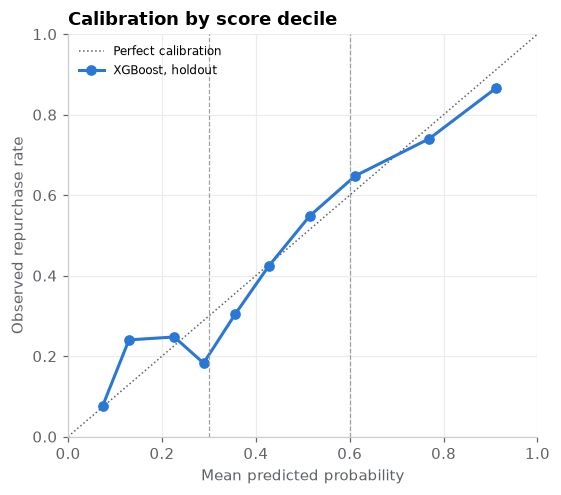

,predicted,observed,customers
0,0.074,0.076,105
1,0.130,0.240,104
2,0.226,0.248,105
3,0.289,0.183,104
4,0.356,0.305,105
5,0.427,0.423,104
6,0.515,0.548,104
7,0.611,0.648,105
8,0.769,0.740,104
9,0.912,0.867,105


In [24]:
cal = calibration_table(y_test, p_test)
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.plot([0, 1], [0, 1], color=MUTED, ls=":", lw=1, label="Perfect calibration")
ax.plot(cal.predicted, cal.observed, color=BLUE, marker="o", lw=2, label="XGBoost, holdout")
for t in (NURTURE_THRESHOLD, LOYAL_THRESHOLD):
    ax.axvline(t, color=GRAY, lw=0.8, ls="--")
ax.set(xlabel="Mean predicted probability", ylabel="Observed repurchase rate", xlim=(0, 1), ylim=(0, 1),
       title="Calibration by score decile")
ax.legend(loc="upper left", fontsize=8)
save(fig, "retention_10_calibration_holdout")
cal

Inside the same period the model is well calibrated: the deciles follow the diagonal, with deviations of a few points that are expected for bands of about 100 customers (Brier score 0.185, against 0.245 for a constant prediction of the base rate). No post-hoc calibration is needed **within** a season. Section 9 shows that this changes across seasons.

### What the segments mean on the test set

In [25]:
seg = pd.Series(np.where(p_test >= LOYAL_THRESHOLD, "Loyal", np.where(p_test >= NURTURE_THRESHOLD, "Nurture", "At risk")), index=test.index)
seg_table = (pd.DataFrame({"segment": seg, "returned": y_test, "p": p_test})
               .groupby("segment").agg(customers=("returned", "size"), predicted=("p", "mean"), actual=("returned", "mean"))
               .reindex(["Loyal", "Nurture", "At risk"]))
seg_table["share_of_customers"] = seg_table.customers / seg_table.customers.sum()
seg_table.style.format({"customers": "{:,}", "predicted": "{:.1%}", "actual": "{:.1%}", "share_of_customers": "{:.1%}"})

,customers,predicted,actual,share_of_customers
segment,,,,
Loyal,266,79.9%,78.2%,25.5%
Nurture,391,44.1%,42.2%,37.4%
At risk,388,16.9%,19.1%,37.1%


The segments separate behaviour clearly: most Loyal customers really do come back, while only a minority of At risk customers do. These are the groups the app turns into campaign lists.

## 9. Out-of-time validation

The real test: train on the **June 2011** snapshot and predict the **September 2011** snapshot, exactly as the model would be used in production (train on the latest complete period, score the next one).

In [26]:
june = snapshots["features_2011_06_01"]
oot_model = make_xgboost().fit(june[FEATURES], june[TARGET])
p_oot = oot_model.predict_proba(df[FEATURES])[:, 1]
oot_logit = make_logistic().fit(june[FEATURES], june[TARGET])
p_oot_logit = oot_logit.predict_proba(df[FEATURES])[:, 1]

oot = pd.DataFrame({
    "Holdout (same period)": evaluate(y_test, p_test),
    "Out of time: XGBoost": evaluate(df[TARGET], p_oot),
    "Out of time: logistic": evaluate(df[TARGET], p_oot_logit),
}).T
oot

,auc,average_precision,brier,log_loss,capture_top20,lift_top20,base_rate,mean_prediction
Holdout (same period),0.786,0.749,0.185,0.551,0.376,1.879,0.428,0.431
Out of time: XGBoost,0.794,0.765,0.196,0.588,0.386,1.930,0.428,0.309
Out of time: logistic,0.789,0.757,0.194,0.579,0.388,1.939,0.428,0.325


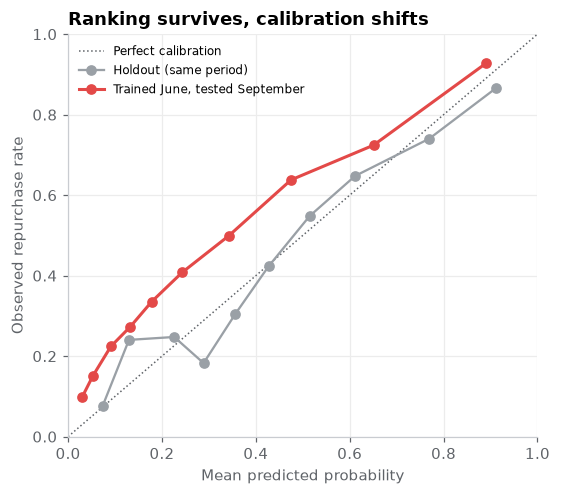

In [27]:
cal_oot = calibration_table(df[TARGET], p_oot)
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.plot([0, 1], [0, 1], color=MUTED, ls=":", lw=1, label="Perfect calibration")
ax.plot(cal.predicted, cal.observed, color=GRAY, marker="o", lw=1.5, label="Holdout (same period)")
ax.plot(cal_oot.predicted, cal_oot.observed, color=RED, marker="o", lw=2, label="Trained June, tested September")
ax.set(xlabel="Mean predicted probability", ylabel="Observed repurchase rate", xlim=(0, 1), ylim=(0, 1),
       title="Ranking survives, calibration shifts")
ax.legend(loc="upper left", fontsize=8)
save(fig, "retention_11_calibration_out_of_time")

**This is the most important finding of the project.**

- **Ranking is stable.** Out-of-time AUC (0.794) is as good as on the holdout, and the top 20% still captures about 39% of buyers. The model has learned durable behaviour, not quirks of one period.
- **Calibration is not.** The June-trained model predicts an average of about 31% while 43% of customers actually returned. The red curve sits above the diagonal everywhere: customers are ranked in the right order, but everyone is more likely to return in autumn than in summer. This is the seasonal base-rate shift found in section 5.1.

**What it means in production.**
1. Use the score first as a **ranking** (who to contact first). That use is robust.
2. Read absolute probabilities and segment sizes with the season in mind. The production model is trained on the September snapshot, the busiest season, and scores customers on 10 December, so the coming quarter (winter) historically has a lower base rate than the training window. Segment sizes will look optimistic; the order of customers will not change.
3. The fix is listed in section 13: recalibrate each season against the expected base rate, or train on several stacked snapshots with a season feature.

## 10. Interpretability with SHAP

A retention team will not act on a score it cannot explain. SHAP (SHapley Additive exPlanations) splits every prediction into a contribution per feature, measured in log-odds, so that the contributions plus a base value add up exactly to the model output. For tree models, TreeSHAP computes these values exactly.

The production model (trained on all September customers) is explained on the customers it will score today.

In [28]:
final_model = make_xgboost().fit(df[FEATURES], df[TARGET])
current = snapshots["features_current"]
explainer = shap.TreeExplainer(final_model)
sv = explainer(current[FEATURES])
sv.feature_names = [FEATURE_LABELS[f] for f in FEATURES]

# The app computes the same values directly with XGBoost; confirm they match.
native = shap_values(final_model, current)
print("Max difference between shap and native XGBoost contributions:",
      float(np.abs(native[FEATURES].values - sv.values).max()))

Max difference between shap and native XGBoost contributions: 0.0


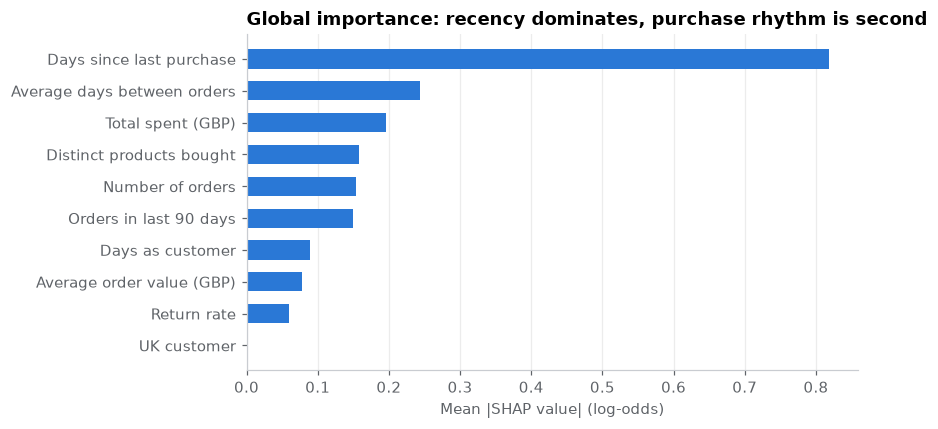

In [29]:
importance = (pd.DataFrame({"feature": sv.feature_names, "mean_abs_shap": np.abs(sv.values).mean(0)})
                .sort_values("mean_abs_shap"))
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(importance.feature, importance.mean_abs_shap, color=BLUE, height=0.6)
ax.set_xlabel("Mean |SHAP value| (log-odds)")
ax.set_title("Global importance: recency dominates, purchase rhythm is second")
ax.grid(axis="y", visible=False)
save(fig, "retention_12_shap_importance")

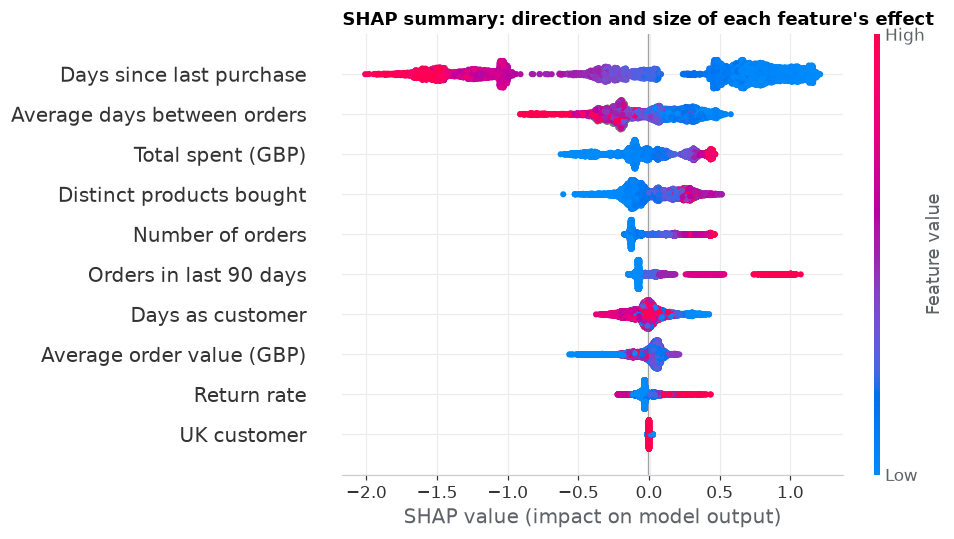

In [30]:
plt.figure()
shap.plots.beeswarm(sv, max_display=10, show=False, color_bar_label="Feature value")
fig = plt.gcf(); fig.set_size_inches(9, 5)
plt.title("SHAP summary: direction and size of each feature's effect", loc="left", fontweight="bold")
save(fig, "retention_13_shap_beeswarm")

**Reading the summary plot.** Each dot is a customer; position shows how much the feature pushed that customer's score up (right) or down (left), and colour shows the feature value.

- **Days since last purchase**: recent customers (low values) are pushed up and long-silent customers are pushed down hard. Its average effect is more than three times that of any other feature.
- **Average days between orders**: customers with a short, regular buying rhythm score higher. Customers with a single order have no rhythm yet; XGBoost routes them as a separate group.
- **Spend, number of orders, recent orders and product variety** add smaller positive effects; because they are correlated, the model spreads the "size of customer" signal across them.
- **Return rate** and the **UK flag** contribute little; they are kept because they cost nothing and the monotone, shallow model does not overfit them.

### Dependence: how the effect of recency changes

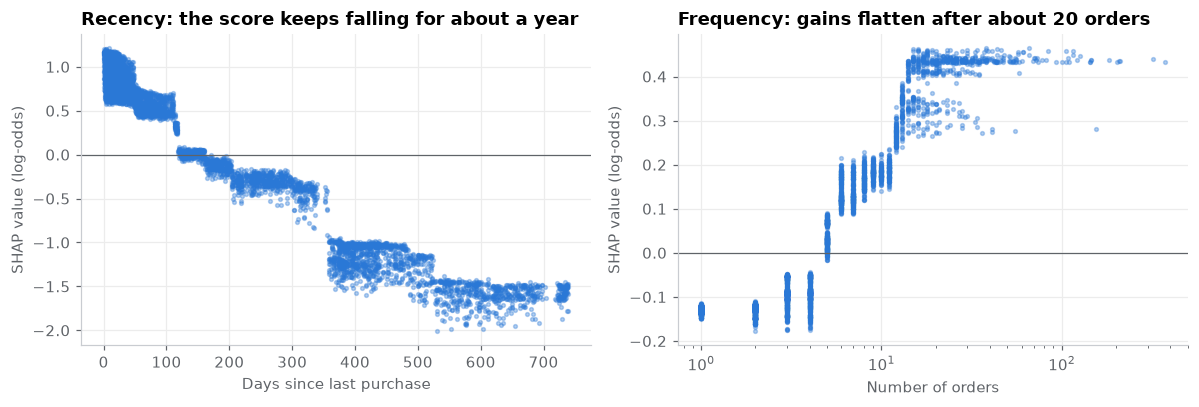

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, f in zip(axes, ["recency_days", "frequency"]):
    i = FEATURES.index(f)
    x = current[f].values
    ax.scatter(x, sv.values[:, i], s=6, alpha=0.35, color=BLUE)
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set_xlabel(FEATURE_LABELS[f]); ax.set_ylabel("SHAP value (log-odds)")
    if f == "frequency":
        ax.set_xscale("log")
axes[0].set_title("Recency: the score keeps falling for about a year")
axes[1].set_title("Frequency: gains flatten after about 20 orders")
save(fig, "retention_14_shap_dependence")

Both curves are monotone by construction (the constraints from section 7) and smooth, which is exactly what the business expects. The recency curve also gives a practical rule: **the contribution turns negative after about five months of silence and keeps falling until about a year**, so the best window for a win-back contact is between three and five months after the last order, before the customer's habit has faded.

### Local explanations: two real customers

Highest-scoring customer: customer 13098, probability 98.3%, last order 2 days ago, 28 orders, £28,882 spent


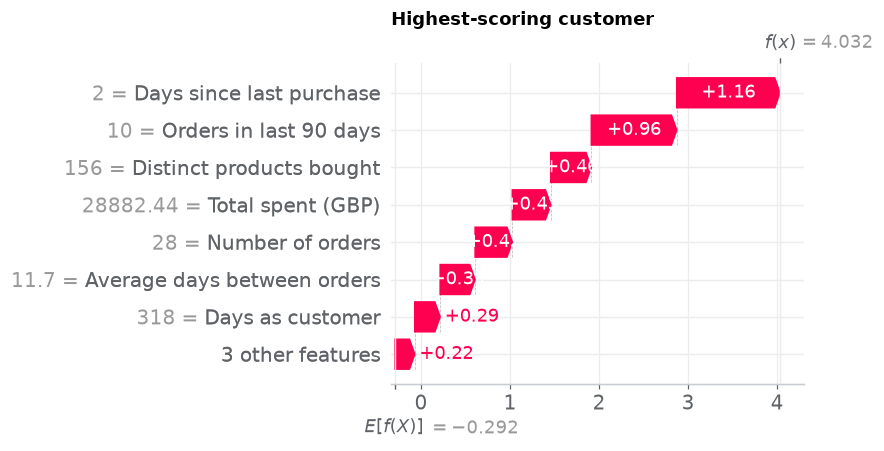

High-value customer at risk: customer 16754, probability 18.3%, last order 373 days ago, 29 orders, £65,500 spent


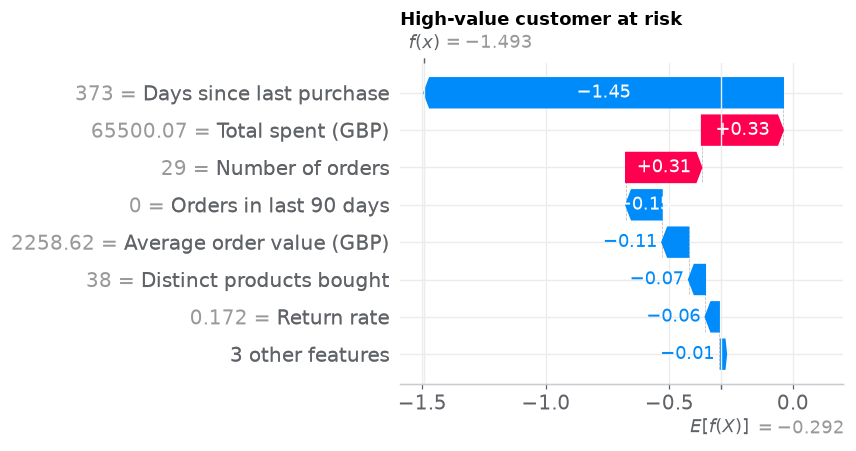

In [32]:
scored_now = current.assign(probability=final_model.predict_proba(current[FEATURES])[:, 1])
high_value_cut = scored_now.monetary.quantile(0.8)
at_risk_vip = scored_now[(scored_now.probability < NURTURE_THRESHOLD) & (scored_now.monetary >= high_value_cut)] \
                .sort_values("monetary", ascending=False).index[0]
loyal = scored_now.probability.idxmax()

for idx, title in [(loyal, "Highest-scoring customer"), (at_risk_vip, "High-value customer at risk")]:
    row = scored_now.loc[idx]
    print(f"{title}: customer {int(row.CustomerID)}, probability {row.probability:.1%}, "
          f"last order {int(row.recency_days)} days ago, {int(row.frequency)} orders, £{row.monetary:,.0f} spent")
    plt.figure()
    shap.plots.waterfall(sv[current.index.get_loc(idx)], max_display=8, show=False)
    fig = plt.gcf(); fig.set_size_inches(8, 4.2)
    plt.title(title, loc="left", fontweight="bold")
    save(fig, "retention_15_shap_waterfall_" + ("loyal" if idx == loyal else "at_risk"))

The waterfall starts at the average model output and adds each feature's contribution until it reaches this customer's score (in log-odds). For the at-risk customer, the long silence outweighs a large historical spend. This is exactly the explanation an account manager needs before calling the customer, and the app shows the same breakdown for every customer.

## 11. Business impact

The production model is applied to all 5,852 customers active before 10 December 2011.

In [33]:
scored_now["segment"] = np.select([scored_now.probability >= LOYAL_THRESHOLD, scored_now.probability >= NURTURE_THRESHOLD],
                                  ["Loyal", "Nurture"], default="At risk")
scored_now["high_value"] = scored_now.monetary >= high_value_cut
impact = (scored_now.groupby("segment")
            .agg(customers=("CustomerID", "size"), avg_probability=("probability", "mean"),
                 high_value_customers=("high_value", "sum"), past_spend=("monetary", "sum"))
            .reindex(["Loyal", "Nurture", "At risk"]))
impact["share_of_spend"] = impact.past_spend / impact.past_spend.sum()
impact.style.format({"customers": "{:,}", "avg_probability": "{:.1%}", "high_value_customers": "{:,}",
                     "past_spend": "£{:,.0f}", "share_of_spend": "{:.1%}"})

,customers,avg_probability,high_value_customers,past_spend,share_of_spend
segment,,,,,
Loyal,"1,862",81.4%,993,"£13,092,882",76.7%
Nurture,"1,703",44.6%,121,"£2,380,905",13.9%
At risk,"2,287",14.4%,57,"£1,595,527",9.3%


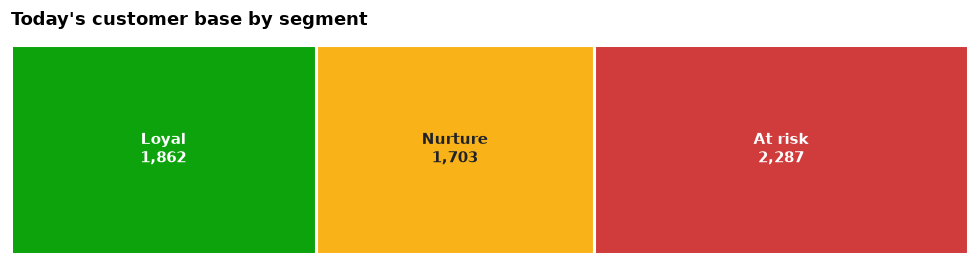

**Priority win-back list:** 57 high-value customers are at risk. Together they spent **£484,715** (2.8% of all historical revenue), and the model gives them an average 18% chance of returning on their own.

In [34]:
fig, ax = plt.subplots(figsize=(9, 2.6))
left = 0
for s in ["Loyal", "Nurture", "At risk"]:
    n = impact.loc[s, "customers"]
    ax.barh([0], [n], left=left, color=STATUS[s], height=0.5, edgecolor="white", linewidth=2)
    ax.text(left + n / 2, 0, f"{s}\n{n:,}", ha="center", va="center", color="white" if s != "Nurture" else INK, fontsize=10, fontweight="bold")
    left += n
ax.set_xlim(0, left); ax.axis("off")
ax.set_title("Today's customer base by segment")
save(fig, "retention_16_segments_today")

vip_risk = scored_now[(scored_now.segment == "At risk") & scored_now.high_value]
display(Markdown(
    f"**Priority win-back list:** {len(vip_risk):,} high-value customers are at risk. "
    f"Together they spent **£{vip_risk.monetary.sum():,.0f}** "
    f"({vip_risk.monetary.sum() / scored_now.monetary.sum():.1%} of all historical revenue), "
    f"and the model gives them an average {vip_risk.probability.mean():.0%} chance of returning on their own."))

**How a campaign would use this.**
- *Priority win-back*: high-value at-risk customers get a personal call from an account manager, with the SHAP explanation as the talking point.
- *Win-back offer*: the remaining at-risk customers get an automated discount email.
- *Nurture*: cross-sell recommendations to lift engagement before they slip.
- *Loyal*: no discount (they are likely to buy anyway, a discount would give margin away); a loyalty reward instead.

**Measuring real impact.** The model predicts who will buy; it does not prove that a campaign *causes* a purchase. Before scaling, each segment should be split into a contacted group and a random holdout group, so the incremental effect of the campaign can be measured (see section 13).

In [35]:
# Numbers quoted in the conclusions, computed rather than typed
h = evaluate(y_test, p_test); o = evaluate(df[TARGET], p_oot)
best = comparison.iloc[0]
display(Markdown(f"""
| Result | Value |
|---|---|
| Customers modelled (training snapshot) | {len(df):,} |
| Cross-validated AUC, chosen model | {comparison.set_index('model').loc['XGBoost (tuned, monotone)', 'auc_mean']:.3f} ± {comparison.set_index('model').loc['XGBoost (tuned, monotone)', 'auc_std']:.3f} |
| Holdout AUC / average precision / Brier | {h['auc']:.3f} / {h['average_precision']:.3f} / {h['brier']:.3f} |
| Top 20% capture and lift (holdout) | {h['capture_top20']:.1%}, {h['lift_top20']:.2f}x |
| Out-of-time AUC | {o['auc']:.3f} |
| Out-of-time mean prediction vs actual | {o['mean_prediction']:.1%} vs {o['base_rate']:.1%} |
| Recency rule AUC (holdout) | {roc_auc_score(y_test, -X_test.recency_days):.3f} |
"""))


| Result | Value |
|---|---|
| Customers modelled (training snapshot) | 5,224 |
| Cross-validated AUC, chosen model | 0.802 ± 0.015 |
| Holdout AUC / average precision / Brier | 0.786 / 0.749 / 0.185 |
| Top 20% capture and lift (holdout) | 37.6%, 1.88x |
| Out-of-time AUC | 0.794 |
| Out-of-time mean prediction vs actual | 30.9% vs 42.8% |
| Recency rule AUC (holdout) | 0.748 |


## 12. Conclusions

1. **The data needed real work before modelling.** About a quarter of the raw lines were removed for documented reasons (anonymous orders, duplicates, non-merchandise codes, accounting entries). Every rule lives in dbt with tests, not in an ad hoc notebook cell.
2. **Leakage was designed out, not hoped away.** Features are built in dbt snapshots with a hard cutoff, and a dbt test fails the build if any feature uses data from the label window.
3. **Behaviour predicts return.** Recency, recent momentum and order frequency dominate, and their effects are monotonic, as the EDA, the model comparison and SHAP all agree.
4. **A simple model is a strong competitor.** Logistic regression is within noise of the best tree model. XGBoost was chosen for production because, at equal accuracy, it adds monotone business constraints, native handling of missing values and exact explanations.
5. **The model is useful for the business.** Contacting the top 20% of customers by score reaches about 38% of future buyers on the holdout and 39% out of time, roughly twice a random list.
6. **Probabilities depend on the season.** Out of time, the ranking survives but the average probability is off by about 12 points because autumn buying is much stronger than summer buying. This is documented, visible in the app, and the first item on the improvement list.

## 13. Limitations and next steps

| Area | Limitation | Next step |
|---|---|---|
| Seasonality | Calibration shifts between seasons | Train on stacked monthly snapshots with a month-of-year feature, or recalibrate (Platt or isotonic) each season against the historical base rate for that quarter |
| Causality | The model predicts purchases, not the effect of a campaign | Run campaigns with random control groups, then move to uplift modelling (T-learner or causal forests) to target customers who change behaviour because of the contact |
| Value | The target is "buys again", not "how much" | Add a spend model (for example BG/NBD plus Gamma-Gamma) to estimate customer lifetime value and rank by expected revenue at risk |
| Features | Only transactional behaviour | Product category mix, price sensitivity, basket trends, seasonality of each customer's own orders |
| Thresholds | Segment cut-offs (0.30, 0.60) are business rules | Optimise thresholds on campaign cost and expected margin once costs are known |
| Data | Ends in December 2011; registered customers only | The pipeline is parameterised by cutoff date, so a new extract only needs `python -m retail_intelligence.features` and `python -m retail_intelligence.train` |
| Monitoring | No live drift checks | Track feature distributions (PSI) and realised repurchase rate per segment each month; retrain when the AUC on the latest labeled period drops |

In [36]:
con.close()